# *Tarbinskiellus portentosus* mitochondrial-genome coverage validation

This notebook reproduces the analysis performed in the chat using the **self-contained custom circular seed/mismatch mapper**. It regenerates per-read placements, per-base Illumina depth, mapping statistics, the lowest-depth 325-bp diagnostic window, primer remapping, TP13 ABI quality trimming/alignment, and publication figures.

**Scope:** the custom mapper is an assembly-validation and coverage-diagnostic script, not the primary assembly program. It uses exact 19-nt seeds and full-read Hamming mismatch scoring and does not model indels. Because the sequencing library was prepared from pooled overlapping PCR amplicons, depth is expected to be strongly non-uniform.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.Align import PairwiseAligner

HERE=Path.cwd()
if (HERE/'raw_data').exists():
    ROOT=HERE
elif (HERE.parent/'raw_data').exists():
    ROOT=HERE.parent
else:
    raise FileNotFoundError('Launch Jupyter from the bundle root or notebooks/ directory.')
RAW=ROOT/'raw_data'; DER=ROOT/'derived_data'; FIG=ROOT/'figures'; SCRIPTS=ROOT/'scripts'
DER.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
sys.path.insert(0,str(SCRIPTS))
print('Bundle root:',ROOT.resolve())

Bundle root: /mnt/data/TP_mitogenome_reproducibility_bundle


## 1. Final circular reference

The deposited GenBank sequence is used as the reference for validation mapping. The D-loop/control-region coordinates are taken from the GenBank annotation.

In [2]:
record=SeqIO.read(RAW/'sequence.gb','genbank')
ref=str(record.seq).upper(); L=len(ref); pos=np.arange(1,L+1)
dloop=(14763,15495)
print('Reference:',record.id)
print('Length:',L,'bp')
print('Topology:',record.annotations.get('topology'))
print('Annotated control region:',dloop)

Reference: PZ447390.1
Length: 15495 bp
Topology: circular
Annotated control region: (14763, 15495)


## 2. Run the exact custom seed/mismatch mapper

The standalone script uses the same parameters as the original analysis:

- 19-nt exact seeds (`K=19`)
- six seed offsets per read
- at most 80 candidate starts ranked by seed votes
- both forward and reverse-complement orientations
- full-read Hamming mismatch scoring, without gapped alignment
- accepted best placement if mismatches ≤12
- circular wrapping across the genome origin

The script writes per-dataset and combined coverage tables, a mapping-statistics JSON file, and a per-read mapping table.

In [3]:
from custom_seed_mismatch_mapper import run_mapping
stats=run_mapping(ROOT,k=19,max_mm=12,max_candidates=80)
print(json.dumps(stats['combined'],indent=2))

{
  "total_reads": 62354,
  "mapped": 54501,
  "unmapped": 7853,
  "mean_depth": 459.0191674733785,
  "median_depth": 292.0,
  "min_depth": 0,
  "max_depth": 2413,
  "covered_1x": 15418,
  "covered_10x": 14596,
  "covered_100x": 12538
}


### Exact result check

In [4]:
expected={
    'total_reads':62354,'mapped':54501,'unmapped':7853,
    'mean_depth':459.0191674733785,'median_depth':292.0,
    'min_depth':0,'max_depth':2413,'covered_1x':15418,
    'covered_10x':14596,'covered_100x':12538,
}
for key,val in expected.items():
    got=stats['combined'][key]
    if isinstance(val,float):
        assert abs(got-val)<1e-9,(key,got,val)
    else:
        assert got==val,(key,got,val)
print('PASS — mapping results exactly reproduce the chat analysis.')

PASS — mapping results exactly reproduce the chat analysis.


## 3. Coverage statistics and lowest-depth 325-bp diagnostic window

In [5]:
cov_all=pd.read_csv(DER/'combined_coverage.tsv',sep='	').depth.to_numpy()
cov1=pd.read_csv(DER/'BAN108_coverage.tsv',sep='	').depth.to_numpy()
cov2=pd.read_csv(DER/'BAN72_coverage.tsv',sep='	').depth.to_numpy()
w=325
sums=np.convolve(cov_all,np.ones(w,dtype=int),'valid')
low_start=int(sums.argmin())+1
low_end=low_start+w-1
low_mean=float(cov_all[low_start-1:low_end].mean())
low_zero=int((cov_all[low_start-1:low_end]==0).sum())
summary={
    'lowest_325_start':low_start,'lowest_325_end':low_end,
    'lowest_325_mean_depth':low_mean,'lowest_325_zero_bases':low_zero,
    'mean_depth':float(cov_all.mean()),'median_depth':float(np.median(cov_all)),
    'min_depth':int(cov_all.min()),'max_depth':int(cov_all.max()),
    'covered_1x':int((cov_all>=1).sum()),
    'covered_10x':int((cov_all>=10).sum()),
    'covered_100x':int((cov_all>=100).sum()),
}
print(json.dumps(summary,indent=2))
assert (low_start,low_end,low_zero)==(14937,15261,77)
pd.DataFrame([{
    'window_length_bp':325,'start_1based':low_start,'end_1based':low_end,
    'mean_depth':low_mean,'zero_depth_bases':low_zero
}]).to_csv(DER/'lowest_coverage_325bp_window.tsv',sep='	',index=False)

{
  "lowest_325_start": 14937,
  "lowest_325_end": 15261,
  "lowest_325_mean_depth": 1.406153846153846,
  "lowest_325_zero_bases": 77,
  "mean_depth": 459.0191674733785,
  "median_depth": 292.0,
  "min_depth": 0,
  "max_depth": 2413,
  "covered_1x": 15418,
  "covered_10x": 14596,
  "covered_100x": 12538
}


**Interpretation:** 14,937–15,261 is the empirically lowest-depth 325-bp window in the final-reference mapping. It is not automatically the exact coordinate of a historical 325-N draft block unless that original N-containing draft is compared directly.

## 4. Remap all 15 primer pairs to the final circular sequence

In [6]:
primer_pairs={
'TP1':('GCTCATACCCCGTTTATAAAGG','CCAATTAATCCAGATCATGCTCC'),
'TP2':('ATCTATCGCCTAAACTTCAGCC','TCAGTGAATGAATCCGGCTATG'),
'TP3':('TGGAGGATTAACCGGAATTGTC','TGGGGCTATTTGTGGAATTAAG'),
'TP4':('AATCACAGTTTCATGCCCATTG','CTGTTGGGGATAGTCTTCTGTG'),
'TP5':('ACCTATCACCGGAGCTATTGG','TGAAGATGTTGGGGAAGTCGT'),
'TP6':('AAGGTTAAGTTAGCAGCTTCCC','ATGACTTCCCGCGGCTATAG'),
'TP7':('TAATTCGCACCCATACCCGA','TTCGTCAAGTGGATTTGAAGTC'),
'TP8':('GTGTACCCAAACGCTCATAAAC','ATTTTGGGGATTGATGATAGGC'),
'TP9':('TGCTTTCGCTTTGAACAATAAAC','TGGAATGGGATTTTGTCAAGGT'),
'TP10':('TGAGTTTGAGGTGGATTTGCA','GGAACAAACTTACCCGATCACT'),
'TP11':('CAGCCAACATCATAGCATACAC','TCTTAAATGTGGGCTTTAAGTTAGC'),
'TP12':('AAACAGGCGAACAATATATTTGC','TAATGTTGGTTAAATGCGTGCC'),
'TP13':('AGCTACACCTTGACCTGACA','CTTTATAAACGGGGTATGAGCC'),
'TP14':('TGTGTTTACGTAATGATTGGGG','AATTCTAATGGTGTGCTTGTGC'),
'TPJ':('TTGCGGATATAACTGTTAGGCC','GTCCACCAATTGATCCGAAAAC')}

def best_circular_hamming(pattern):
    pattern=pattern.upper(); n=len(pattern); circ=ref+ref[:n-1]
    best_pos=None; best_mm=n+1
    for i in range(L):
        window=circ[i:i+n]
        mm=sum(a!=b for a,b in zip(pattern,window))
        if mm<best_mm:
            best_mm=mm; best_pos=i+1
    return best_pos,best_mm

rows=[]
for name,(fwd,rev) in primer_pairs.items():
    f_start,f_mm=best_circular_hamming(fwd)
    r_binding=str(Seq(rev).reverse_complement())
    r_start,r_mm=best_circular_hamming(r_binding)
    r_end=((r_start+len(rev)-2)%L)+1
    wraps=f_start>r_end
    length=(r_end-f_start+1) if not wraps else (L-f_start+1)+r_end
    rows.append({'amplicon':name,'start':f_start,'end':r_end,'length_final':length,
                 'wraps_origin':wraps,'F_mismatches':f_mm,'R_mismatches':r_mm})
amp=pd.DataFrame(rows)
amp.to_csv(DER/'primer_amplicons_remapped_to_final_genome.csv',index=False)
display(amp)

,amplicon,start,end,length_final,wraps_origin,F_mismatches,R_mismatches
0,TP1,160,1478,1319,False,0,0
1,TP2,1368,2577,1210,False,0,0
2,TP3,2439,3836,1398,False,0,1
3,TP4,3609,4984,1376,False,0,1
4,TP5,4704,6232,1529,False,0,0
5,TP6,6088,7387,1300,False,0,0
6,TP7,7202,8617,1416,False,0,0
7,TP8,8429,9815,1387,False,0,0
8,TP9,9624,11023,1400,False,0,0
9,TP10,10848,12335,1488,False,0,0


## 5. TP13 ABI quality trimming and circular alignment

In [7]:
abi_trim=SeqIO.read(RAW/'TP13-TP13FR.ab1','abi-trim')
q=str(Seq(str(abi_trim.seq)).reverse_complement()).upper()
quals=abi_trim.letter_annotations['phred_quality']
aligner=PairwiseAligner()
aligner.mode='local'; aligner.match_score=2; aligner.mismatch_score=-1
aligner.open_gap_score=-5; aligner.extend_gap_score=-1
aln=aligner.align(ref+ref,q)[0]
blocks=aln.aligned[0]
sanger_start0=int(blocks[0][0])
sanger_end_unwrapped=int(blocks[-1][1])
sanger_start=sanger_start0+1
sanger_end_wrapped=((sanger_end_unwrapped-1)%L)+1
target=(ref+ref)[sanger_start0:sanger_start0+len(q)]
sanger_mm=sum(a!=b for a,b in zip(q,target))
sanger=pd.DataFrame([{
    'source':'TP13-TP13FR.ab1','parser':'abi-trim','trimmed_length_bp':len(q),
    'orientation':'reverse-complement','alignment_start_1based':sanger_start,
    'alignment_end_unwrapped_1based':sanger_end_unwrapped,
    'alignment_end_wrapped_1based':sanger_end_wrapped,
    'crosses_origin':sanger_end_unwrapped>L,'mismatches':sanger_mm,
    'mean_phred':float(np.mean(quals)),'bases_phred_ge_20':int(sum(x>=20 for x in quals))
}])
sanger.to_csv(DER/'TP13_sanger_qtrim_alignment_summary.tsv',sep='	',index=False)
display(sanger)
assert (sanger_start,sanger_end_wrapped,len(q),sanger_mm)==(14968,123,651,1)

,source,parser,trimmed_length_bp,orientation,alignment_start_1based,alignment_end_unwrapped_1based,alignment_end_wrapped_1based,crosses_origin,mismatches,mean_phred,bases_phred_ge_20
0,TP13-TP13FR.ab1,abi-trim,651,reverse-complement,14968,15618,123,True,1,47.552995,630


The TP13 Sanger sequence is plotted as a separate evidence track. It is **not** converted into artificial Illumina depth.

## 6. Plotting helper

In [8]:
def save_both(fig,name):
    fig.savefig(FIG/f'{name}.png',dpi=600,bbox_inches='tight')
    fig.savefig(FIG/f'{name}.pdf',bbox_inches='tight')

## 7. Original full-genome combined coverage

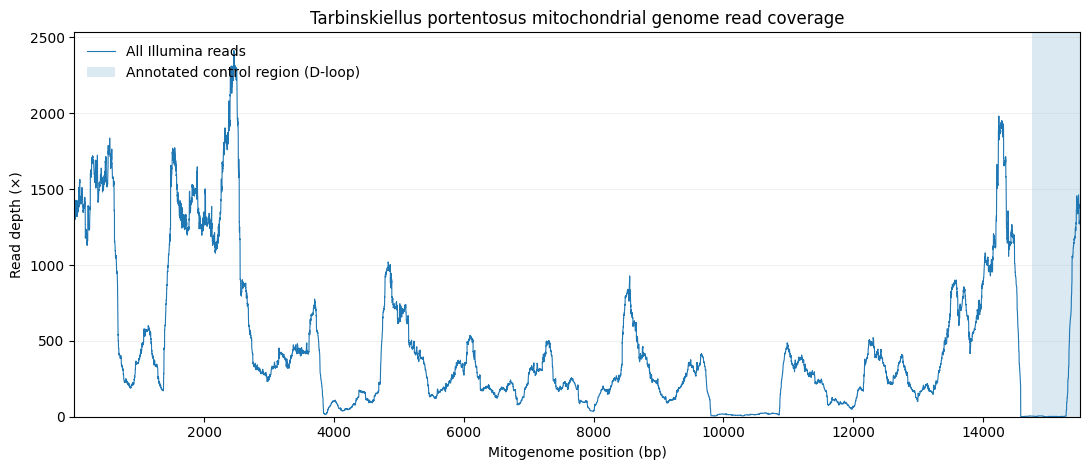

In [9]:
fig,ax=plt.subplots(figsize=(11,4.8))
ax.plot(pos,cov_all,linewidth=0.8,label='All Illumina reads')
ax.axvspan(dloop[0],dloop[1],alpha=0.16,label='Annotated control region (D-loop)')
ax.set_xlim(1,L); ax.set_ylim(bottom=0)
ax.set_xlabel('Mitogenome position (bp)'); ax.set_ylabel('Read depth (×)')
ax.set_title('Tarbinskiellus portentosus mitochondrial genome read coverage')
ax.grid(axis='y',alpha=0.22,linewidth=0.6); ax.legend(frameon=False,loc='upper left')
fig.tight_layout(); save_both(fig,'TP_mitogenome_coverage_all_reads'); plt.show()

## 8. Original control-region zoom with the diagnostic 325-bp window

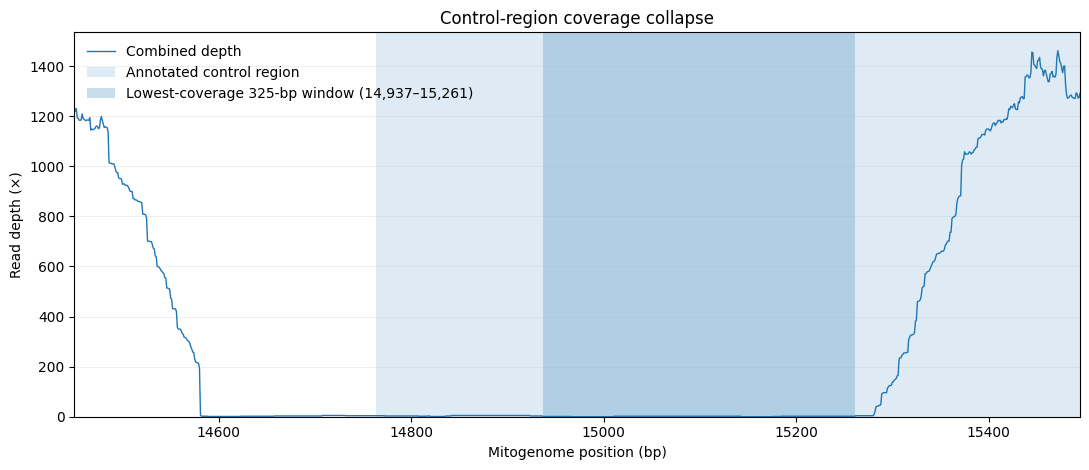

In [10]:
lo=14450; mask=(pos>=lo)&(pos<=L)
fig,ax=plt.subplots(figsize=(11,4.8))
ax.plot(pos[mask],cov_all[mask],linewidth=1.0,label='Combined depth')
ax.axvspan(dloop[0],dloop[1],alpha=0.14,label='Annotated control region')
ax.axvspan(low_start,low_end,alpha=0.24,label=f'Lowest-coverage 325-bp window ({low_start:,}–{low_end:,})')
ax.set_xlim(lo,L); ax.set_ylim(bottom=0)
ax.set_xlabel('Mitogenome position (bp)'); ax.set_ylabel('Read depth (×)')
ax.set_title('Control-region coverage collapse')
ax.grid(axis='y',alpha=0.22,linewidth=0.6); ax.legend(frameon=False,loc='upper left')
fig.tight_layout(); save_both(fig,'TP_control_region_coverage_zoom'); plt.show()

## 9. Dataset-specific coverage

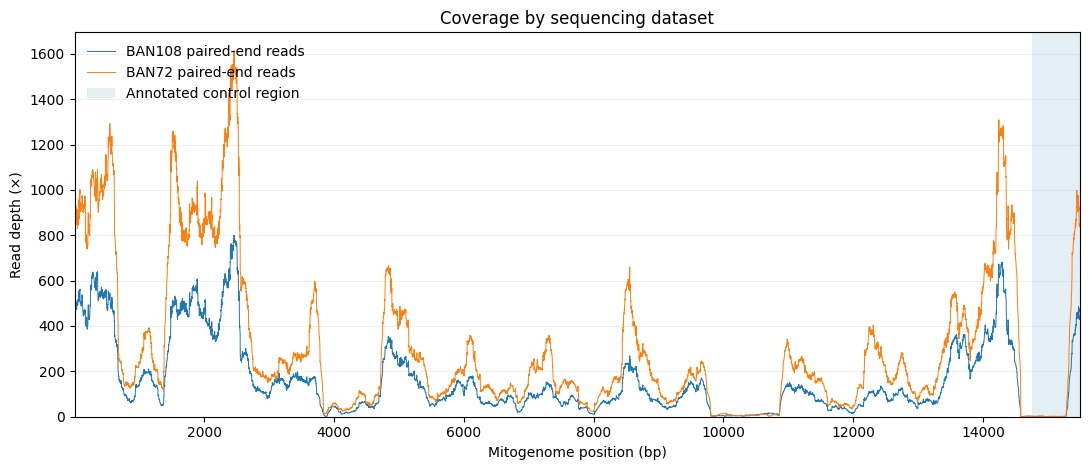

In [11]:
fig,ax=plt.subplots(figsize=(11,4.8))
ax.plot(pos,cov1,linewidth=0.7,label='BAN108 paired-end reads')
ax.plot(pos,cov2,linewidth=0.7,label='BAN72 paired-end reads')
ax.axvspan(dloop[0],dloop[1],alpha=0.12,label='Annotated control region')
ax.set_xlim(1,L); ax.set_ylim(bottom=0)
ax.set_xlabel('Mitogenome position (bp)'); ax.set_ylabel('Read depth (×)')
ax.set_title('Coverage by sequencing dataset')
ax.grid(axis='y',alpha=0.22,linewidth=0.6); ax.legend(frameon=False,loc='upper left')
fig.tight_layout(); save_both(fig,'TP_mitogenome_coverage_by_dataset'); plt.show()

## 10. Recommended whole-genome figure: coverage + amplicon design + TP13 Sanger

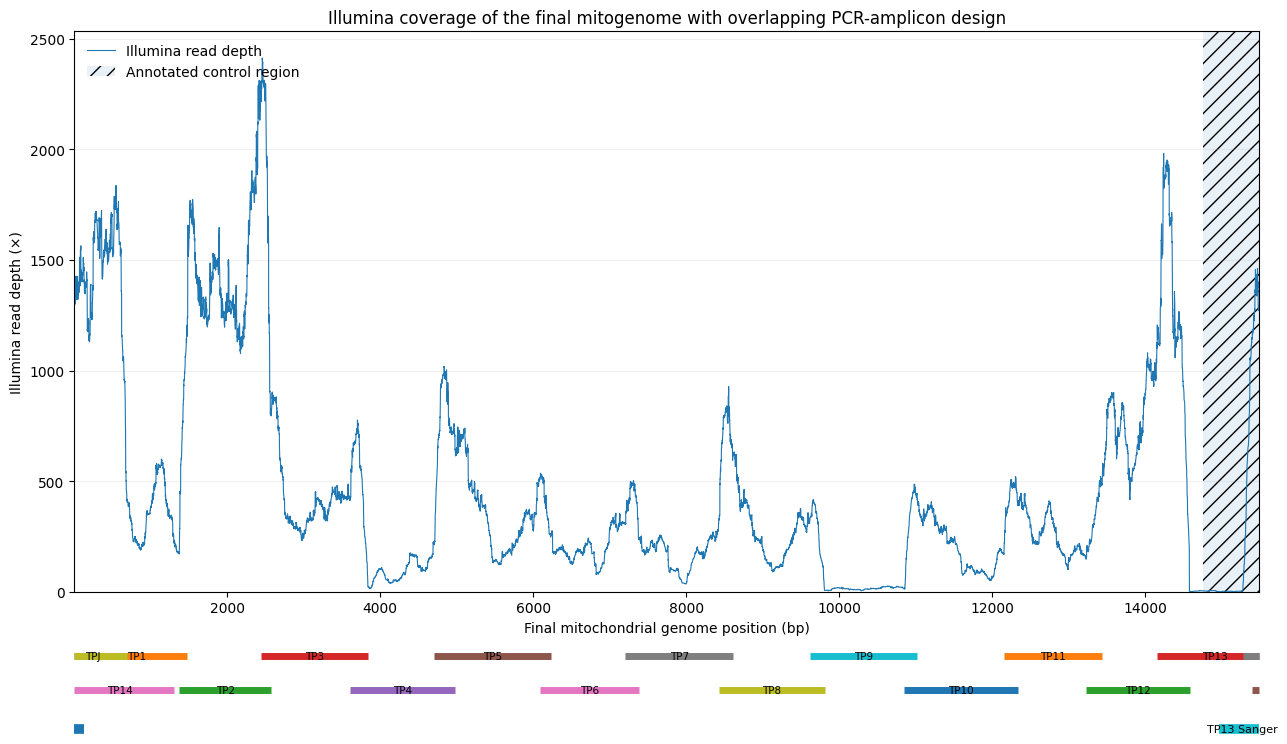

In [12]:
fig,ax=plt.subplots(figsize=(13,7.2))
ax.plot(pos,cov_all,linewidth=0.8,label='Illumina read depth')
ax.axvspan(dloop[0],dloop[1],alpha=0.10,hatch='//',label='Annotated control region')
ax.set_xlim(1,L); ax.set_ylim(0,cov_all.max()*1.05)
ax.set_xlabel('Final mitochondrial genome position (bp)'); ax.set_ylabel('Illumina read depth (×)')
ax.set_title('Illumina coverage of the final mitogenome with overlapping PCR-amplicon design')
ax.grid(axis='y',alpha=0.18)
row_y=[-0.115,-0.175]
for i,row in amp.iterrows():
    y=row_y[i%2]; start=int(row['start']); end=int(row['end'])
    if bool(row['wraps_origin']):
        ax.plot([start,L],[y,y],transform=ax.get_xaxis_transform(),linewidth=5,solid_capstyle='butt',clip_on=False)
        ax.plot([1,end],[y,y],transform=ax.get_xaxis_transform(),linewidth=5,solid_capstyle='butt',clip_on=False)
        mid=((start+((L-start+1+end)/2)-1)%L)+1
    else:
        ax.plot([start,end],[y,y],transform=ax.get_xaxis_transform(),linewidth=5,solid_capstyle='butt',clip_on=False)
        mid=(start+end)/2
    ax.text(mid,y,row['amplicon'],transform=ax.get_xaxis_transform(),ha='center',va='center',fontsize=7.5,clip_on=False)
y=-0.245
ax.plot([sanger_start,L],[y,y],transform=ax.get_xaxis_transform(),linewidth=7,solid_capstyle='butt',clip_on=False)
ax.plot([1,sanger_end_wrapped],[y,y],transform=ax.get_xaxis_transform(),linewidth=7,solid_capstyle='butt',clip_on=False)
ax.text(15270,y,'TP13 Sanger',transform=ax.get_xaxis_transform(),ha='center',va='center',fontsize=8,clip_on=False)
ax.legend(frameon=False,loc='upper left')
fig.subplots_adjust(bottom=0.30); fig.tight_layout()
save_both(fig,'TP_coverage_with_amplicon_design_qtrim'); plt.show()

## 11. Recommended control-region/origin figure

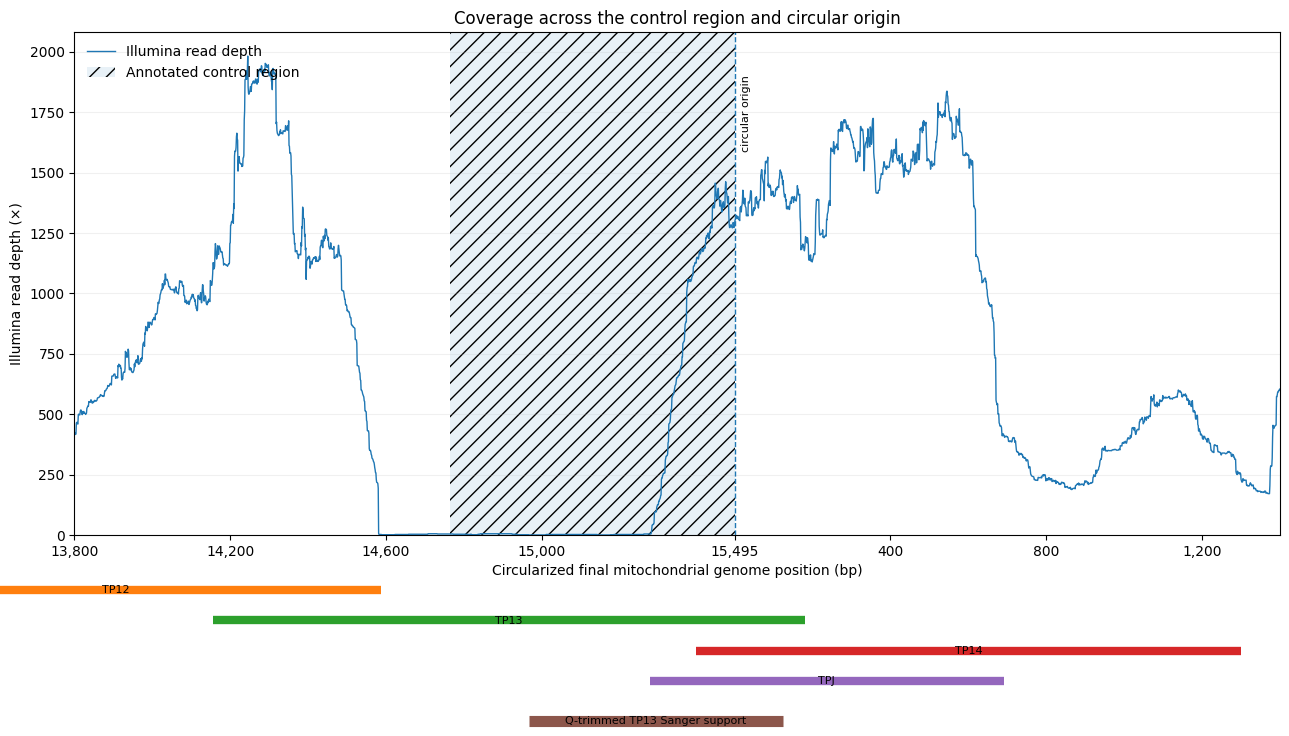

In [13]:
zoom_start=13800; zoom_after_origin=1400
m1=pos>=zoom_start; m2=pos<=zoom_after_origin
left=pd.DataFrame({'position':pos[m1],'depth':cov_all[m1]}); left['x']=left['position']
right=pd.DataFrame({'position':pos[m2],'depth':cov_all[m2]}); right['x']=right['position']+L
zoom=pd.concat([left,right],ignore_index=True)
fig,ax=plt.subplots(figsize=(13,7.0))
ax.plot(zoom['x'],zoom['depth'],linewidth=1.0,label='Illumina read depth')
ax.axvspan(dloop[0],L,alpha=0.10,hatch='//',label='Annotated control region')
ax.axvline(L,linestyle='--',linewidth=1.0)
ax.text(L+15,zoom['depth'].max()*0.96,'circular origin',rotation=90,va='top',ha='left',fontsize=8)
for name,y in zip(['TP12','TP13','TP14','TPJ'],[-0.11,-0.17,-0.23,-0.29]):
    r=amp.loc[amp['amplicon']==name].iloc[0]
    start=int(r['start']); end=int(r['end']); end_u=L+end if bool(r['wraps_origin']) else end
    ax.plot([start,end_u],[y,y],transform=ax.get_xaxis_transform(),linewidth=6,solid_capstyle='butt',clip_on=False)
    ax.text((start+end_u)/2,y,name,transform=ax.get_xaxis_transform(),ha='center',va='center',fontsize=8,clip_on=False)
y=-0.37; sanger_end_u=L+sanger_end_wrapped
ax.plot([sanger_start,sanger_end_u],[y,y],transform=ax.get_xaxis_transform(),linewidth=8,solid_capstyle='butt',clip_on=False)
ax.text((sanger_start+sanger_end_u)/2,y,'Q-trimmed TP13 Sanger support',transform=ax.get_xaxis_transform(),ha='center',va='center',fontsize=8,clip_on=False)
ax.set_xlim(zoom_start,L+zoom_after_origin); ax.set_ylim(0,zoom['depth'].max()*1.05)
ax.set_xlabel('Circularized final mitochondrial genome position (bp)'); ax.set_ylabel('Illumina read depth (×)')
ax.set_title('Coverage across the control region and circular origin'); ax.grid(axis='y',alpha=0.18)
ticks=[13800,14200,14600,15000,L,L+400,L+800,L+1200]
ax.set_xticks(ticks); ax.set_xticklabels([f'{t:,}' if t<=L else f'{t-L:,}' for t in ticks])
ax.legend(frameon=False,loc='upper left'); fig.subplots_adjust(bottom=0.34); fig.tight_layout()
save_both(fig,'TP_control_region_amplicons_Sanger_qtrim'); plt.show()

## 12. Output inventory

In [14]:
print('Derived data files:')
for p in sorted(DER.iterdir()):
    print(' -',p.name)
print()
print('Figure files:')
for p in sorted(FIG.iterdir()):
    print(' -',p.name)

Derived data files:
 - BAN108_coverage.tsv
 - BAN72_coverage.tsv
 - TP13_sanger_qtrim_alignment_summary.tsv
 - combined_coverage.tsv
 - coverage_summary.txt
 - lowest_coverage_325bp_window.tsv
 - mapping_stats.json
 - primer_amplicons_remapped_to_final_genome.csv
 - read_mappings.tsv

Figure files:
 - TP_control_region_Sanger_support_redesigned.pdf
 - TP_control_region_Sanger_support_redesigned.png
 - TP_control_region_amplicons_Sanger.pdf
 - TP_control_region_amplicons_Sanger.png
 - TP_control_region_amplicons_Sanger_qtrim.pdf
 - TP_control_region_amplicons_Sanger_qtrim.png
 - TP_control_region_coverage_zoom.pdf
 - TP_control_region_coverage_zoom.png
 - TP_coverage_with_amplicon_design.pdf
 - TP_coverage_with_amplicon_design.png
 - TP_coverage_with_amplicon_design_qtrim.pdf
 - TP_coverage_with_amplicon_design_qtrim.png
 - TP_mitogenome_coverage_all_reads.pdf
 - TP_mitogenome_coverage_all_reads.png
 - TP_mitogenome_coverage_by_dataset.pdf
 - TP_mitogenome_coverage_by_dataset.png
 - TP_